In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 202607
rng = np.random.default_rng(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

In [97]:
n = [20, 200, 2000]
B = 2_000
exp = stats.expon(1)
samples = [np.zeros(shape=(n[i], B)) for i in range(len(n))]
for j in range(len(n)):
    for sim_id in range(B):
        for i in range(n[j]):
            samples[j][i, sim_id] = rng.exponential()


In [98]:
def bias(sample: np.ndarray, q: float) -> float:
    estimates = np.array([np.mean(sample[:, i]) for i in range(np.shape(sample)[1])])
    estimates -= q
    return sum(estimates) / len(estimates)

In [99]:
for i in range(len(n)):
    print(n[i],":", float(bias(samples[i], 1)))

20 : -0.004727760159552152
200 : 0.0017037301867349622
2000 : -1.734739566550042e-05


In [100]:
def rmse(sample: np.ndarray, q: float) -> float:
    estimates = np.array([np.mean(sample[:, i]) for i in range(np.shape(sample)[1])])
    estimates -= q
    rmse = np.sqrt(np.sum(estimates ** 2)/len(estimates))
    return rmse


In [101]:
for i in range(len(n)):
    print(n[i],":", float(rmse(samples[i], 1)))

20 : 0.22690726916824122
200 : 0.06918972905818457
2000 : 0.02258197417503241


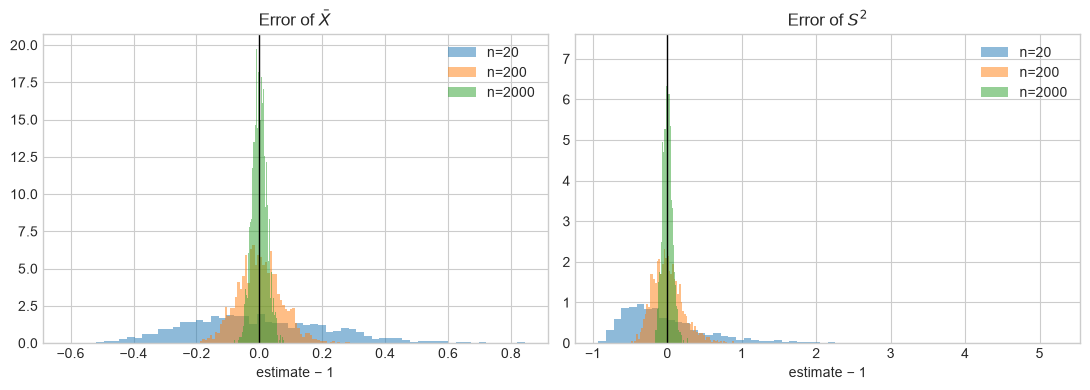

In [102]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for j in range(len(n)):
    s = samples[j]
    ax[0].hist(s.mean(axis=0) - 1, bins=60, density=True, alpha=0.5, label=f"n={n[j]}")
    ax[1].hist(s.var(axis=0, ddof=1) - 1, bins=60, density=True, alpha=0.5, label=f"n={n[j]}")
ax[0].set_title(r"Error of $\bar X$")
ax[1].set_title(r"Error of $S^2$")
for a_ in ax:
    a_.axvline(0, color="k", lw=1)
    a_.set_xlabel("estimate − 1")
    a_.legend()
plt.tight_layout()
plt.show()

In [103]:
a = samples[1][:, rng.integers(B)].copy()
mn1 = np.mean(a)
md1 = np.median(a)
var1 = np.var(a, ddof=1)
a[rng.integers(n[1])] = 100
mn2 = np.mean(a)
md2 = np.median(a)
var2 = np.var(a, ddof=1)
print("Variance:", var1, "->", var2)
print("Mean:", mn1, "->", mn2)
print("Median:", md1, "->", md2)

Variance: 0.7177128266028583 -> 49.821042528157264
Mean: 0.8989457517917963 -> 1.3958348119671444
Median: 0.6835745685395676 -> 0.6966429344182855
